In [1]:
import pandas as pd

df = pd.read_csv("airline_passenger_satisfaction.csv")
categorical_df = df.select_dtypes(exclude="number")
numerical_df = df.select_dtypes(include="number")

# check we didn't miss anything along the way
assert len(df.columns.to_list()) == len(categorical_df.columns.to_list()) + len(numerical_df.columns.to_list())

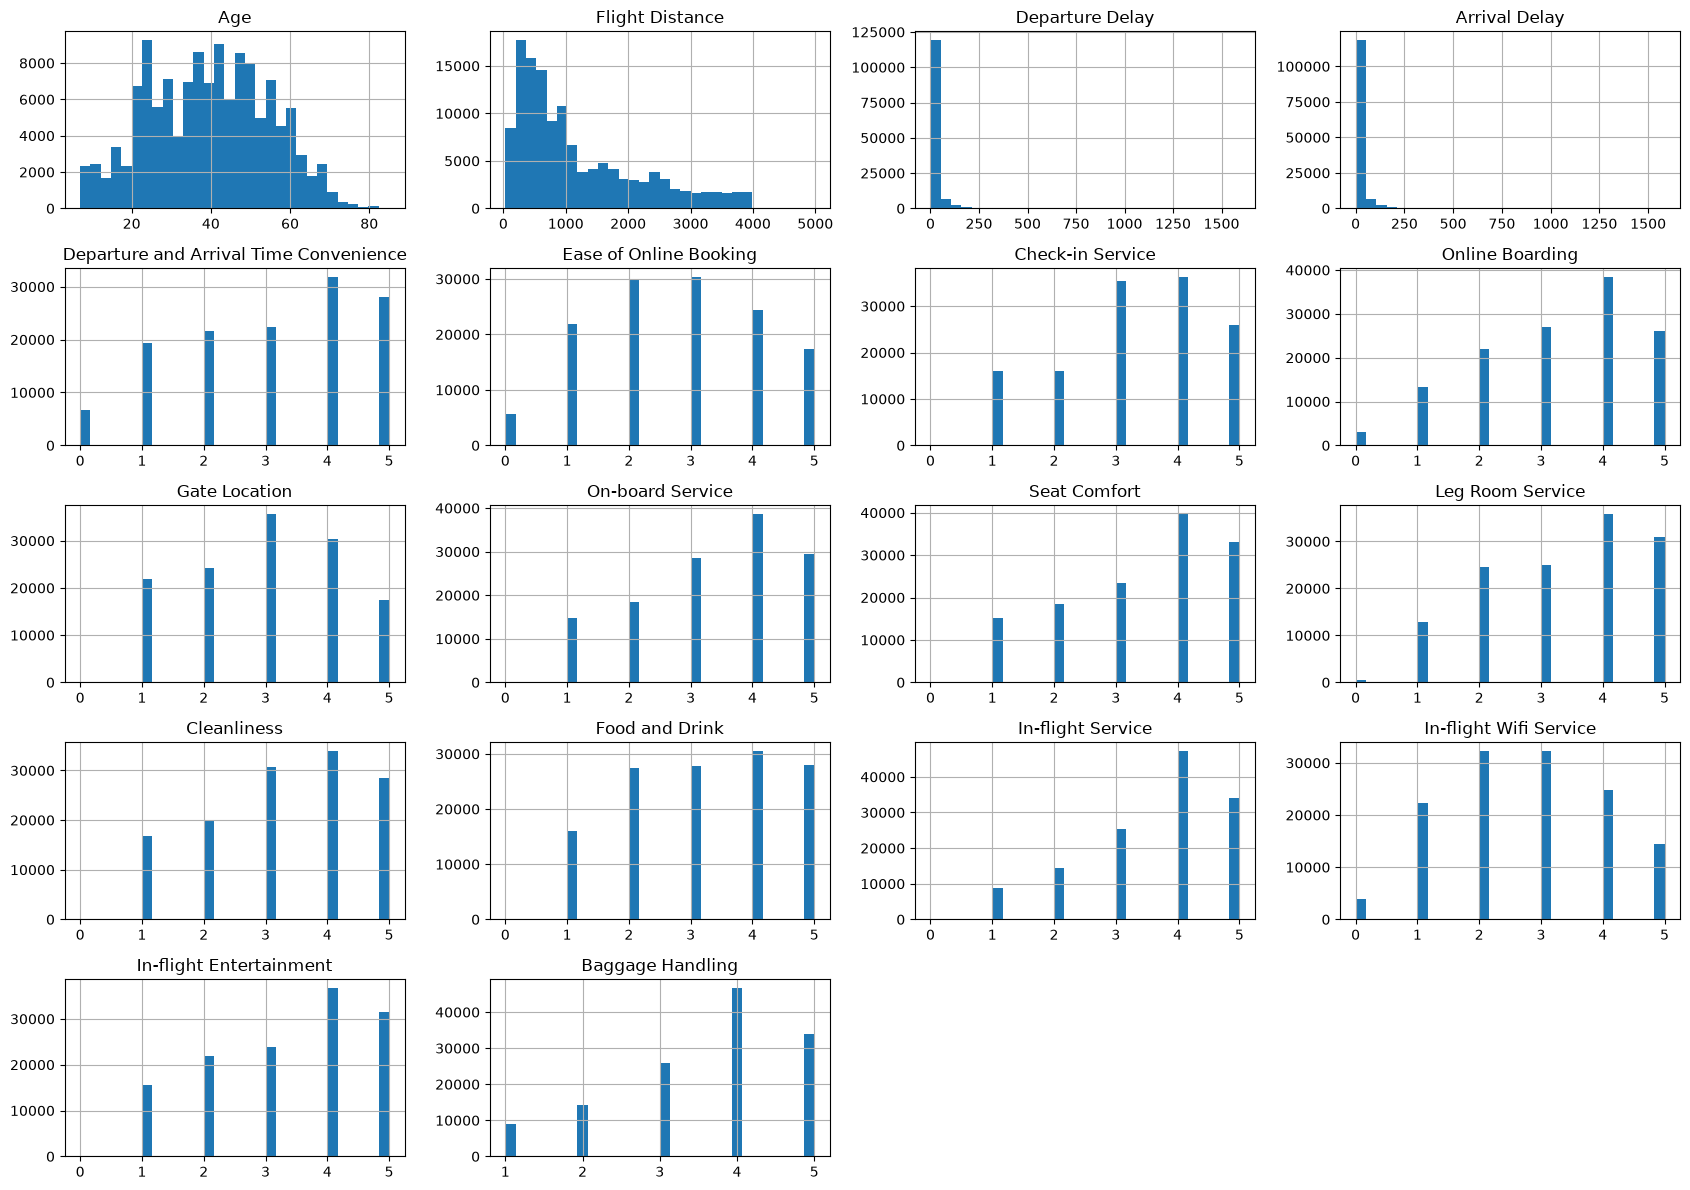

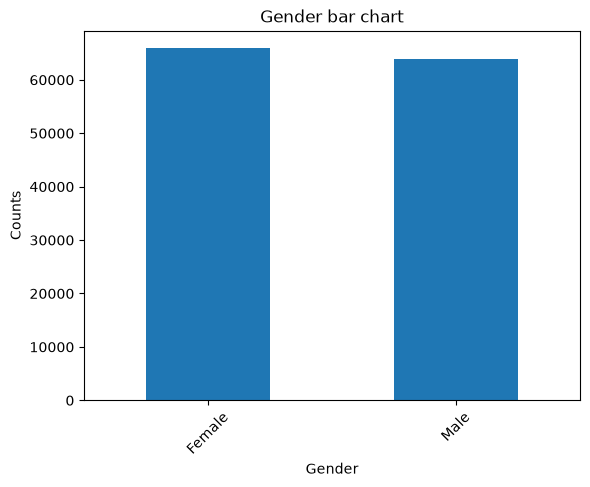

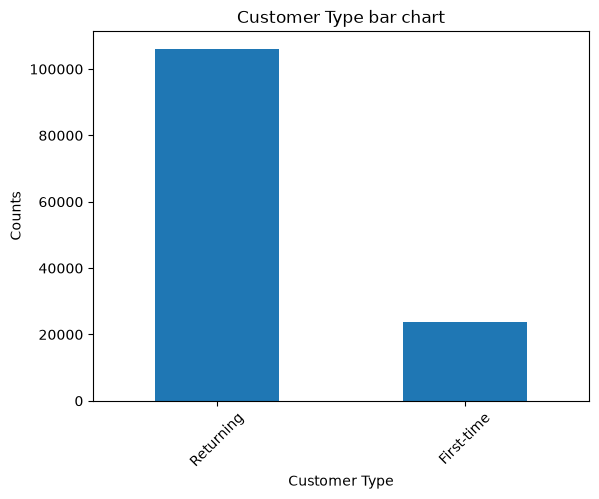

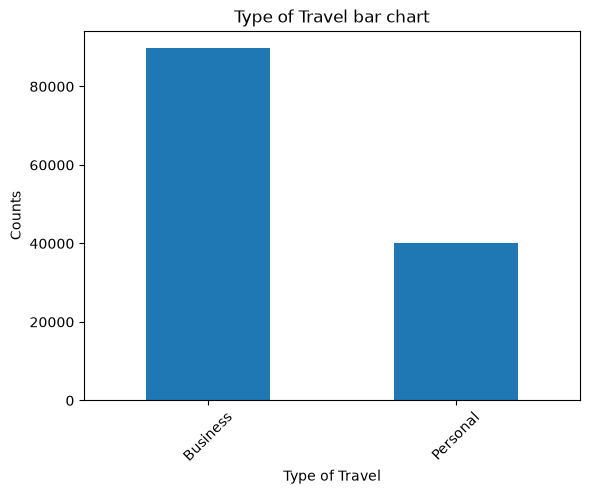

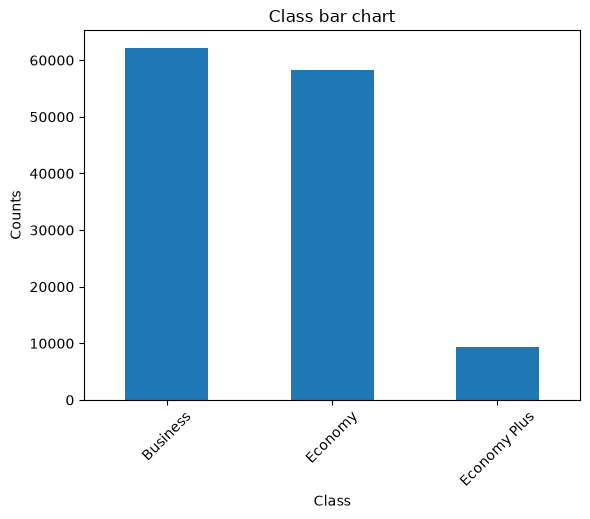

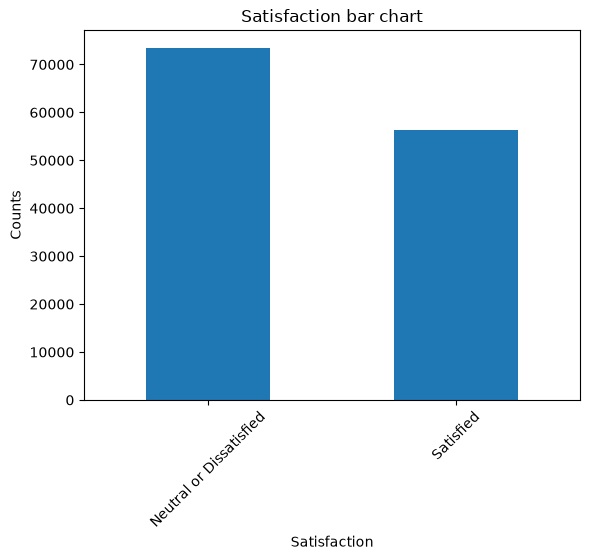

In [2]:
import matplotlib.pyplot as plt

# for name, _ in numerical_df.items():
#     if name.lower() == "id":
#         continue
#     numerical_df[name].hist(bins=30, edgecolor="black")
#     plt.title(f"{name} historgram")
#     plt.xlabel(name)
#     plt.ylabel("Counts")
#     plt.grid(False)
#     plt.show()

# this creates a grid of graphs instead of several big ones
numerical_df.drop(columns=["ID"]).hist(figsize=(17, 12), bins=30)
plt.tight_layout()
plt.show()

# grid of graphs is not as straight forward for bar plots, so here we do create several big ones
for name, _ in categorical_df.items():
    categorical_df[name].value_counts().plot(kind="bar", rot=45)
    plt.title(f"{name} bar chart")
    plt.xlabel(name)
    plt.ylabel("Counts")
    plt.grid(False)
    plt.show()

In [3]:
# Παρατηρούμε ότι οι κλάσσεις "Customer type", "Type of travel" και "Class" είναι μη-ισορροπημηνες κλάσσεις. Συγκεκριμένα:
# Customer type: Η συντριπτική πλειοψηφία αποτελούν returning customers
# Type of travel: Τα business travels είναι πολύ περισσότερα από τα personal
# Class: Η "economy plus" έχει ελάχιστη παρουσία σε σχέση με την business και την economy

In [15]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


Y = LabelEncoder().fit_transform(df["Satisfaction"])

train_pct = 0.7
test_pct = 0.3
x_train, x_test, y_train, y_test = train_test_split(df, Y, test_size=test_pct, random_state=0)

ct = ColumnTransformer(
    transformers=[
        ("ordinal", OrdinalEncoder(categories=[["Economy", "Economy Plus", "Business"]]), ["Class"]),
        # for columns like Gender which is binary we can drop one of the two columns for efficiency
        ("onehot", OneHotEncoder(drop="if_binary"), ["Type of Travel", "Gender", "Customer Type"]),

        # get the numerical columns names and pass them to StandardScaler
        # We have to do scaling to the numerical columns because their values differ
        # by many orders of magnitude - for example 
        # the leg room goes from 0 to 5, whereas flight distance goes from 0 to 5000
        ("scaling", StandardScaler(), numerical_df.columns.drop(["ID"])),
        
        # drop columns we don't want in our training
        ("drop", "drop", ["Satisfaction", "ID"])
    ],
    remainder="passthrough",
)

pipeline = Pipeline([
    ("preprocess", ct),
])

pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['ID','Gender','Age',...,'In-flight Entertainment','Baggage Handling', 'Satisfaction']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinal', ...), ('onehot', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset o